# 03 稠相网络阈值分析

读取第二步生成的链对接触 NPZ，计算网络指标并绘制 PPT 图。居中与链对接触计算已移出 notebook。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from IPython.display import Image, display

ROOT = Path("..")
if not (ROOT / "results").is_dir():
    raise FileNotFoundError("请从本文件夹的 notebook/ 目录启动 Jupyter")
RESULTS = ROOT / "results"
OUTPUT_DIR = ROOT / "figures/03_network"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VARIANTS = ("A18", "B01", "B10")
COLORS = {"A18": "#858a92", "B01": "#3774b7", "B10": "#ce7137"}
THRESHOLDS = (1, 5, 10, 20, 30, 35, 40, 50, 75, 100)
BLOCK_FRAMES = 50


### 网络指标计算


In [2]:
def graph_stats(adjacency: np.ndarray) -> tuple[float, float]:
    """Return global efficiency and largest-component share."""
    n = len(adjacency)
    if n < 2:
        return np.nan, np.nan
    distances = shortest_path(csr_matrix(adjacency), directed=False,
                              unweighted=True)
    inv = np.zeros_like(distances, dtype=float)
    finite = np.isfinite(distances) & (distances > 0)
    inv[finite] = 1.0 / distances[finite]
    efficiency = float(inv.sum() / (n * (n - 1)))
    count, labels = connected_components(csr_matrix(adjacency), directed=False)
    largest_fraction = float(np.bincount(labels, minlength=count).max() / n)
    return efficiency, largest_fraction

def analyze_variant(variant: str, path: Path, block_frames: int) -> pd.DataFrame:
    with np.load(path) as saved:
        contacts = saved["contact_counts"]
        dense_pairs = saved["both_dense"]
    n_pairs = contacts.shape[1]
    n_chains = round((1 + np.sqrt(1 + 8 * n_pairs)) / 2)
    if n_chains * (n_chains - 1) // 2 != n_pairs:
        raise ValueError(f"{variant}: unexpected chain-pair count")
    pair_i, pair_j = np.triu_indices(n_chains, 1)
    rows = []
    for fi, (count, eligible) in enumerate(zip(contacts, dense_pairs)):
        dense = np.zeros(n_chains, dtype=bool)
        dense[pair_i[eligible]] = True
        dense[pair_j[eligible]] = True
        indices = np.flatnonzero(dense)
        for threshold in THRESHOLDS:
            pair_edge = eligible & (count >= threshold)
            full = np.zeros((n_chains, n_chains), dtype=bool)
            full[pair_i[pair_edge], pair_j[pair_edge]] = True
            full[pair_j[pair_edge], pair_i[pair_edge]] = True
            efficiency, giant = graph_stats(
                full[np.ix_(indices, indices)])
            rows.append({
                "variant": variant, "frame": fi, "block": fi // block_frames,
                "threshold": threshold,
                "global_efficiency": efficiency,
                "largest_component_fraction": giant,
            })
    return pd.DataFrame(rows)


### 从 NPZ 计算 PPT 图所需的时间块网络指标


In [3]:
rows = pd.concat([
    analyze_variant(v, RESULTS / f"{v}_edge_arrays.npz", BLOCK_FRAMES)
    for v in VARIANTS
], ignore_index=True)
assert all(rows.loc[rows.variant.eq(v), "frame"].nunique() == 750 for v in VARIANTS)
blocks = rows.groupby(["variant", "threshold", "block"], as_index=False)[
    ["global_efficiency", "largest_component_fraction"]
].mean()


### PPT 用双面图


In [4]:
"""Slide-size Python figure for the T260 graph-threshold result.

Core question: does the B01/B10 ordering depend on how many residue contacts
define a chain edge? Panel a is the primary result (efficiency), panel b checks
whether stronger filtering fragments the network. Block-SD is descriptive,
not replicate-based uncertainty. White, wide, editable-text SVG/PDF export.
"""

OUTPUT = OUTPUT_DIR / "graph_threshold_for_slide"
ppt_blocks = blocks[blocks.threshold <= 75]

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "svg.fonttype": "none", "pdf.fonttype": 42, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.35), constrained_layout=True)
for ax, metric, label in zip(
    axes,
    ("global_efficiency", "largest_component_fraction"),
    ("Global efficiency", "Largest component / dense chains"),
):
    for variant in ("A18", "B01", "B10"):
        sub = ppt_blocks[ppt_blocks.variant == variant]
        stat = sub.groupby("threshold")[metric].agg(["mean", "std"])
        x = stat.index.to_numpy(dtype=float)
        y = stat["mean"].to_numpy()
        sd = stat["std"].to_numpy()
        ax.plot(x, y, "-o", ms=4.2, lw=2.1, color=COLORS[variant],
                label=variant)
        ax.fill_between(x, np.maximum(y - sd, 0), np.minimum(y + sd, 1),
                        color=COLORS[variant], alpha=0.10, linewidth=0)
    ax.set(xlabel="Minimum residue contacts per chain pair", ylabel=label,
           xlim=(0, 77), xticks=[1, 10, 20, 30, 40, 50, 75])
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylim(0, 0.62)
axes[1].set_ylim(0, 1.04)
axes[0].legend(loc="upper right", title="Variant")
for label, ax in zip("ab", axes):
    ax.text(-0.12, 1.05, label, transform=ax.transAxes,
            fontweight="bold", fontsize=11)

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT.with_suffix(".svg"), bbox_inches="tight")
fig.savefig(OUTPUT.with_suffix(".pdf"), bbox_inches="tight")
plt.close(fig)


### 查看图

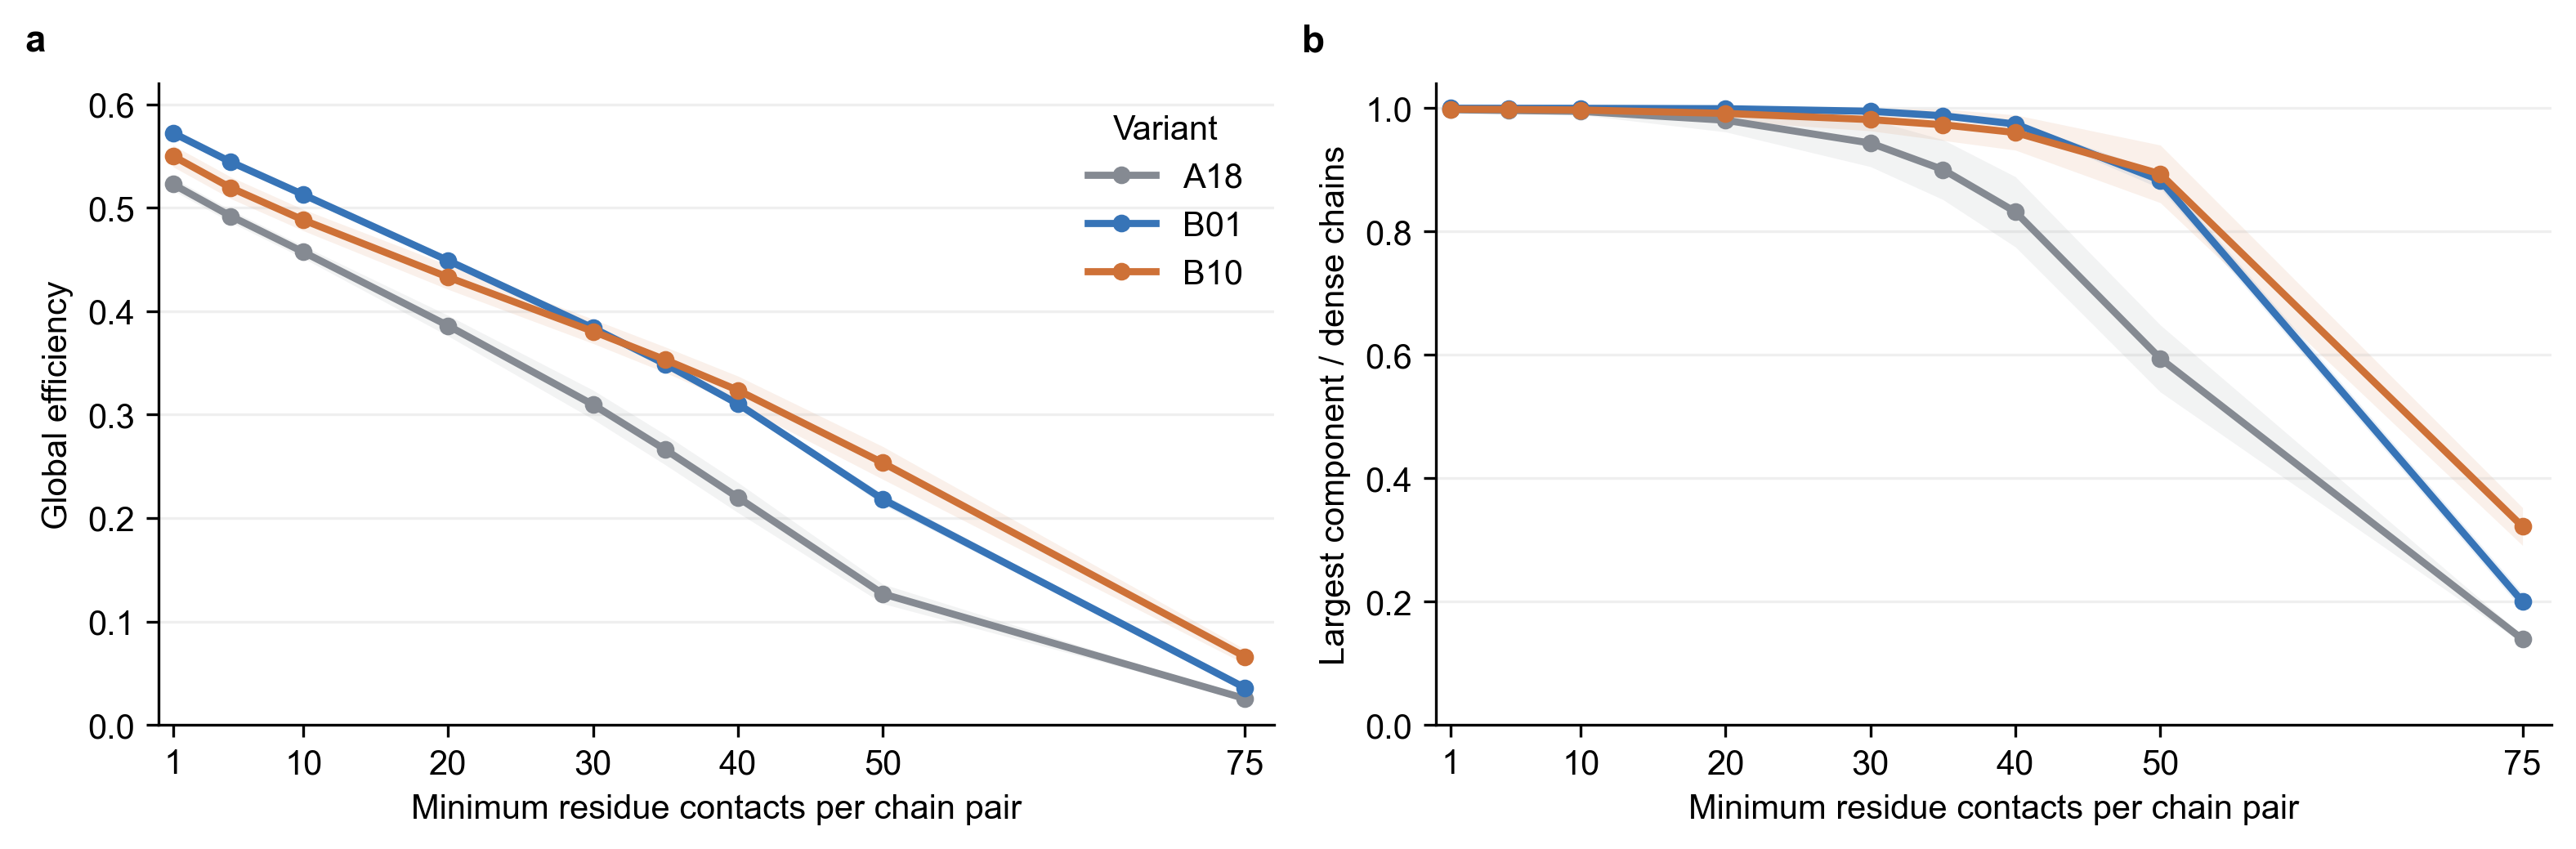

In [5]:
display(Image(filename=str(OUTPUT_DIR / "graph_threshold_for_slide.png")))
